# Task 30: Manual Confusion Matrix Analysis

## Objective
To calculate and visualize confusion matrices manually for classification
models, compare their performance, and analyze false positives and
false negatives without using built-in confusion matrix functions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna().reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (302, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  


In [2]:
feature_columns = [
    col for col in df.select_dtypes(include=["number"]).columns
    if col != "target"
]

X = df[feature_columns].to_numpy(dtype=float)
y_original = df["target"].to_numpy()

classes = np.unique(y_original)

if len(classes) != 2:
    raise ValueError("This notebook expects a binary target.")

y = (y_original == classes[1]).astype(int)


def manual_stratified_split(X, y, train_ratio=0.8, random_seed=42):
    rng = np.random.default_rng(random_seed)
    train_indices = []
    test_indices = []

    for target_value in np.unique(y):
        indices = np.where(y == target_value)[0].copy()
        rng.shuffle(indices)

        split_index = int(len(indices) * train_ratio)
        train_indices.extend(indices[:split_index])
        test_indices.extend(indices[split_index:])

    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)

    rng.shuffle(train_indices)
    rng.shuffle(test_indices)

    return (
        X[train_indices],
        X[test_indices],
        y[train_indices],
        y[test_indices]
    )


X_train, X_test, y_train, y_test = manual_stratified_split(X, y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (241, 13)
Testing set: (61, 13)


In [3]:
def manual_confusion_matrix(y_true, y_pred):
    tn = 0
    fp = 0
    fn = 0
    tp = 0

    for actual, predicted in zip(y_true, y_pred):
        if actual == 0 and predicted == 0:
            tn += 1
        elif actual == 0 and predicted == 1:
            fp += 1
        elif actual == 1 and predicted == 0:
            fn += 1
        elif actual == 1 and predicted == 1:
            tp += 1

    return np.array([
        [tn, fp],
        [fn, tp]
    ])


def manual_metrics(y_true, y_pred):
    matrix = manual_confusion_matrix(y_true, y_pred)

    tn, fp = matrix[0]
    fn, tp = matrix[1]

    total = tn + fp + fn + tp

    accuracy = (tp + tn) / total if total else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }

In [4]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# Scale using training data only
means = np.mean(X_train, axis=0)
stds = np.std(X_train, axis=0)
stds[stds == 0] = 1

X_train_scaled = (X_train - means) / stds
X_test_scaled = (X_test - means) / stds


def train_logistic_regression(X, y, learning_rate=0.01, epochs=2000):
    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    for _ in range(epochs):
        probabilities = sigmoid(X @ weights + bias)
        errors = probabilities - y

        dw = (X.T @ errors) / n_samples
        db = np.sum(errors) / n_samples

        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias


weights, bias = train_logistic_regression(
    X_train_scaled, y_train
)

logistic_probabilities = sigmoid(X_test_scaled @ weights + bias)
logistic_predictions = (
    logistic_probabilities >= 0.5
).astype(int)

print("Logistic Regression predictions completed.")

Logistic Regression predictions completed.


In [5]:
def manual_gini(y_values):
    if len(y_values) == 0:
        return 0

    counts = {}

    for label in y_values:
        counts[label] = counts.get(label, 0) + 1

    impurity = 1.0

    for count in counts.values():
        probability = count / len(y_values)
        impurity -= probability ** 2

    return impurity


def find_best_split(X, y, min_samples_split=10):
    n_samples, n_features = X.shape

    if n_samples < min_samples_split:
        return None

    parent_gini = manual_gini(y)
    best_gain = 0
    best_split = None

    for feature_index in range(n_features):
        unique_values = np.unique(X[:, feature_index])

        if len(unique_values) < 2:
            continue

        thresholds = (
            unique_values[:-1] + unique_values[1:]
        ) / 2

        for threshold in thresholds:
            left_mask = X[:, feature_index] <= threshold
            right_mask = ~left_mask

            if not left_mask.any() or not right_mask.any():
                continue

            y_left = y[left_mask]
            y_right = y[right_mask]

            weighted_gini = (
                len(y_left) / n_samples * manual_gini(y_left)
                + len(y_right) / n_samples * manual_gini(y_right)
            )

            gain = parent_gini - weighted_gini

            if gain > best_gain:
                best_gain = gain
                best_split = {
                    "feature_index": feature_index,
                    "threshold": float(threshold),
                    "left_mask": left_mask,
                    "right_mask": right_mask,
                    "gain": gain
                }

    return best_split


def build_tree(
    X, y, depth=0, max_depth=4, min_samples_split=10
):
    labels, counts = np.unique(y, return_counts=True)
    majority_class = int(labels[np.argmax(counts)])

    if (
        len(labels) == 1
        or depth >= max_depth
        or len(y) < min_samples_split
    ):
        return {"leaf": True, "prediction": majority_class}

    split = find_best_split(
        X, y, min_samples_split
    )

    if split is None or split["gain"] <= 0:
        return {"leaf": True, "prediction": majority_class}

    left_mask = split["left_mask"]
    right_mask = split["right_mask"]

    return {
        "leaf": False,
        "feature_index": split["feature_index"],
        "threshold": split["threshold"],
        "left": build_tree(
            X[left_mask], y[left_mask],
            depth + 1, max_depth, min_samples_split
        ),
        "right": build_tree(
            X[right_mask], y[right_mask],
            depth + 1, max_depth, min_samples_split
        )
    }


def predict_one(node, row):
    if node["leaf"]:
        return node["prediction"]

    if row[node["feature_index"]] <= node["threshold"]:
        return predict_one(node["left"], row)

    return predict_one(node["right"], row)


def predict_tree(tree, X):
    return np.array([
        predict_one(tree, row) for row in X
    ])


tree = build_tree(
    X_train, y_train,
    max_depth=4,
    min_samples_split=10
)

tree_predictions = predict_tree(tree, X_test)

print("Decision Tree predictions completed.")

Decision Tree predictions completed.


In [6]:
logistic_matrix = manual_confusion_matrix(
    y_test, logistic_predictions
)

tree_matrix = manual_confusion_matrix(
    y_test, tree_predictions
)

print("Logistic Regression Confusion Matrix:")
print(logistic_matrix)

print("\nDecision Tree Confusion Matrix:")
print(tree_matrix)

Logistic Regression Confusion Matrix:
[[22  6]
 [ 5 28]]

Decision Tree Confusion Matrix:
[[22  6]
 [12 21]]


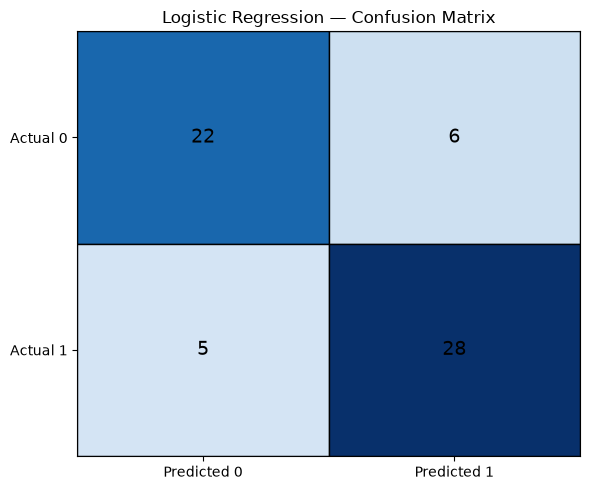

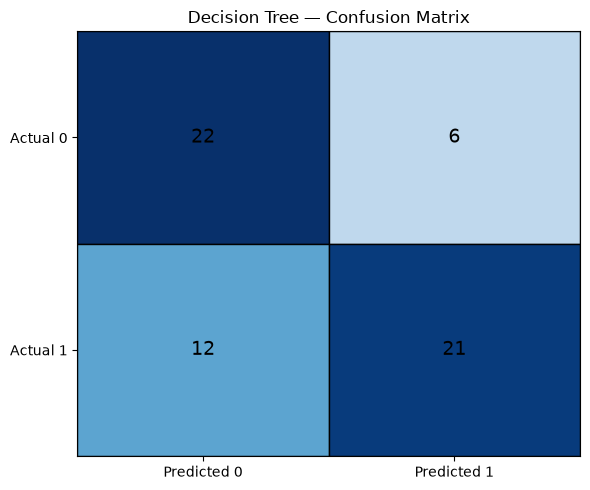

In [7]:
def plot_manual_confusion_matrix(matrix, title):
    fig, ax = plt.subplots(figsize=(6, 5))

    maximum = max(1, int(np.max(matrix)))

    for i in range(2):
        for j in range(2):
            value = int(matrix[i, j])

            rect = plt.Rectangle(
                (j, i),
                1,
                1,
                facecolor=plt.cm.Blues(value / maximum),
                edgecolor="black"
            )

            ax.add_patch(rect)

            ax.text(
                j + 0.5,
                i + 0.5,
                str(value),
                ha="center",
                va="center",
                fontsize=14
            )

    ax.set_xlim(0, 2)
    ax.set_ylim(2, 0)

    ax.set_xticks([0.5, 1.5])
    ax.set_yticks([0.5, 1.5])

    ax.set_xticklabels(["Predicted 0", "Predicted 1"])
    ax.set_yticklabels(["Actual 0", "Actual 1"])

    ax.set_title(title)

    plt.tight_layout()
    plt.show()


plot_manual_confusion_matrix(
    logistic_matrix,
    "Logistic Regression — Confusion Matrix"
)

plot_manual_confusion_matrix(
    tree_matrix,
    "Decision Tree — Confusion Matrix"
)

In [8]:
logistic_metrics = manual_metrics(
    y_test, logistic_predictions
)

tree_metrics = manual_metrics(
    y_test, tree_predictions
)

comparison = pd.DataFrame([
    {"Model": "Logistic Regression", **logistic_metrics},
    {"Model": "Decision Tree", **tree_metrics}
])

print(comparison.round(4).to_string(index=False))

print("\nMisclassification Analysis:")
print(
    "Logistic Regression — False Positives:",
    logistic_metrics["FP"],
    "| False Negatives:",
    logistic_metrics["FN"]
)

print(
    "Decision Tree — False Positives:",
    tree_metrics["FP"],
    "| False Negatives:",
    tree_metrics["FN"]
)

              Model  TN  FP  FN  TP  Accuracy  Precision  Recall  F1-score
Logistic Regression  22   6   5  28    0.8197     0.8235  0.8485    0.8358
      Decision Tree  22   6  12  21    0.7049     0.7778  0.6364    0.7000

Misclassification Analysis:
Logistic Regression — False Positives: 6 | False Negatives: 5
Decision Tree — False Positives: 6 | False Negatives: 12


## Conclusion

Confusion matrices were calculated manually for Logistic Regression
and Decision Tree models. Their true negatives, false positives,
false negatives, and true positives were compared alongside accuracy,
precision, recall, and F1-score.

False positives and false negatives represent different types of
classification errors. Their practical importance depends on the
application. These educational models are not intended for medical
diagnosis.